### Import Library

In [27]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.inspection import permutation_importance
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

### Memuat data siap pakai dari hasil Tahap 6

In [28]:
X_train, X_test, y_train, y_test = joblib.load('../dataset/step_06_ready_for_model.pkl')
print("Data berhasil dimuat! Ukuran X_train:", X_train.shape)

Data berhasil dimuat! Ukuran X_train: (3891, 12)


### Mencari Nilai K Terbaik Berdasarkan R2 Score

In [29]:
k_values = range(1, 16)
r2_scores = []

for k in k_values:
    knn_temp = KNeighborsRegressor(n_neighbors=k)
    knn_temp.fit(X_train, y_train)
    y_pred_temp = knn_temp.predict(X_test)
    r2_scores.append(r2_score(y_test, y_pred_temp))

best_k = k_values[np.argmax(r2_scores)]
print(f"Nilai K terbaik adalah: {best_k} dengan R2 Score: {max(r2_scores):.4f}")

Nilai K terbaik adalah: 7 dengan R2 Score: 0.6355


### Visualisasi nilai K vs R2 Score

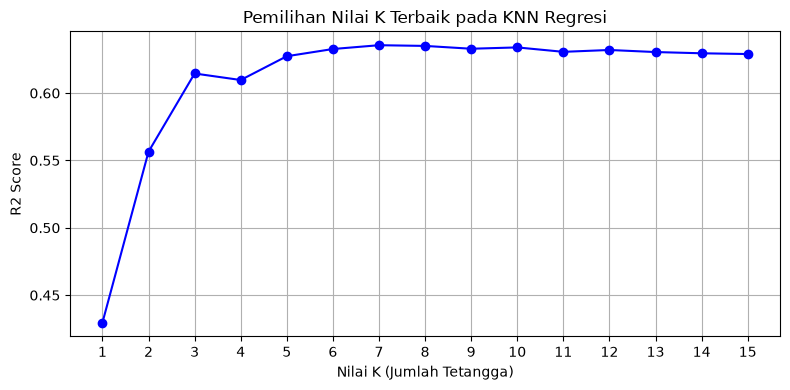

In [30]:
plt.figure(figsize=(8, 4))
plt.plot(k_values, r2_scores, marker='o', linestyle='-', color='b')
plt.title('Pemilihan Nilai K Terbaik pada KNN Regresi')
plt.xlabel('Nilai K (Jumlah Tetangga)')
plt.ylabel('R2 Score')
plt.xticks(k_values)
plt.grid(True)
plt.tight_layout()
plt.show()

### Melatih Model KNN Regresi Final

In [31]:
start_time = time.perf_counter()

model_knn = KNeighborsRegressor(n_neighbors=best_k)
model_knn.fit(X_train, y_train)
y_pred_knn = model_knn.predict(X_test)

end_time = time.perf_counter()

waktu_knn = end_time - start_time

print("Model Berhasil Dibuat!")
print(f"Waktu Eksekusi Model KNN Regresi: {waktu_knn:.4f} detik")

Model Berhasil Dibuat!
Waktu Eksekusi Model KNN Regresi: 0.0646 detik


### Evaluasi

In [32]:
r2_knn   = r2_score(y_test, y_pred_knn)
mae_knn  = mean_absolute_error(y_test, y_pred_knn)
rmse_knn = np.sqrt(mean_squared_error(y_test, y_pred_knn))
mape_knn = mean_absolute_percentage_error(y_test, y_pred_knn) * 100 # Dalam persen (%)

print("=== HASIL EVALUASI MODEL KNN REGRESI ===")
print(f"1. R2 Score       : {r2_knn:.4f} ({r2_knn*100:.2f}%)")
print(f"2. MAE            : Rp {mae_knn:,.2f}")
print(f"3. RMSE           : Rp {rmse_knn:,.2f}")
print(f"4. MAPE           : {mape_knn:.2f}%")
print(f"5. Waktu Eksekusi : {waktu_knn:.4f} detik")

=== HASIL EVALUASI MODEL KNN REGRESI ===
1. R2 Score       : 0.6355 (63.55%)
2. MAE            : Rp 592,470,320.07
3. RMSE           : Rp 790,880,790.58
4. MAPE           : 143.50%
5. Waktu Eksekusi : 0.0646 detik


### Perbandingan Harga Aktual dan Prediksi

In [33]:
df_perbandingan_harga = pd.DataFrame({
    'Aktual': y_test.values,
    'Prediksi': y_pred_knn
})

display(df_perbandingan_harga.head(10))

,Aktual,Prediksi
0,2400000000,1.707143e+09
1,3400000000,2.804286e+09
2,2270000000,3.292857e+09
3,2480000000,3.104286e+09
4,1400000000,1.671429e+09
5,1350000000,2.261429e+09
6,4600000000,3.792857e+09
7,1600000000,2.346429e+09
8,2100000000,3.514286e+09
9,2200000000,2.271429e+09


### Visualisasi Perbandingan Harga Aktual dan Prediksi

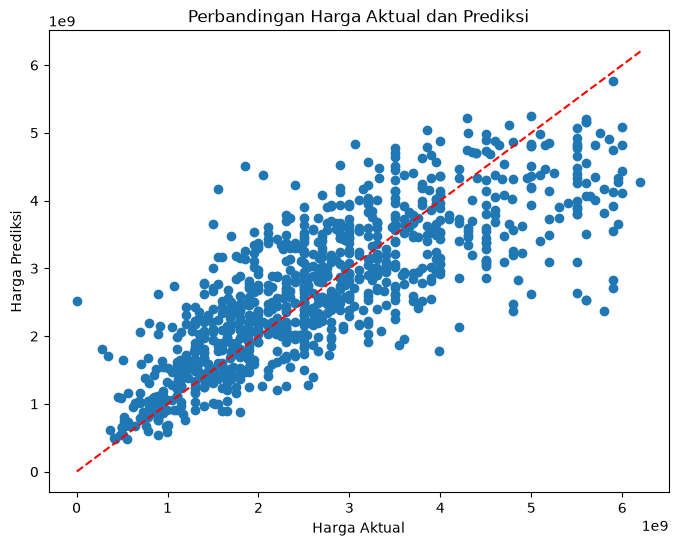

In [34]:
plt.figure(figsize=(8,6))

plt.scatter(y_test, y_pred_knn)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel('Harga Aktual')
plt.ylabel('Harga Prediksi')
plt.title('Perbandingan Harga Aktual dan Prediksi')

plt.show()

### Analisis Feature Importance pada KNN

In [35]:
# Mengambil nama kolom fitur dari step 5 
df_step5 = joblib.load('../dataset/step_05_selected.pkl')
nama_fitur = df_step5.drop(columns=['price']).columns

# Menghitung tingkat kepentingan fitur (importance) pada model KNN
perm_importance = permutation_importance(model_knn, X_test, y_test, n_repeats=5, random_state=42)

feature_importance = pd.DataFrame({
    'Fitur': nama_fitur,
    'Importance': perm_importance.importances_mean
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

display(feature_importance)

,Fitur,Importance
11,total_area,0.116781
5,land_area,0.107261
6,building_area,0.097778
1,city,0.070211
0,district,0.051359
3,bath_rooms,0.038042
9,remaining_land,0.031061
4,carport,0.022612
2,bed_rooms,0.020802
8,building_ratio,0.020658


### Menyimpan Hasil KNN Regres

In [36]:
hasil_knn_reg = {
    'Model': 'KNN',
    'R2': r2_knn,
    'MAE': mae_knn,
    'RMSE': rmse_knn,
    'MAPE (%)': mape_knn,
    'Waktu (Detik)': waktu_knn,
    'y_test': y_test,
    'y_pred': y_pred_knn
}

joblib.dump(hasil_knn_reg, 'hasil_knn.pkl')
print("Hasil evaluasi KNN Regresi berhasil disimpan ke 'regresi_model/hasil_knn.pkl'!")

Hasil evaluasi KNN Regresi berhasil disimpan ke 'regresi_model/hasil_knn.pkl'!
